# Homework 3.2 Solutions | Sampling and the Central Limit Theorem

*Homework is designed to both test your knowledge and challenge you to apply familiar concepts in new applications. Answer clearly and completely. You are welcomed and encouraged to work in groups so long as your work is your own. Submit your figures and answers to [Gradescope](https://www.gradescope.com).*

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Fix the random draws so the numbers match these solutions
np.random.seed(150)

## Q1. The Central Limit Theorem with a Normal Population

The wait times (in minutes) at a restaurant follow a normal distribution with mean $\mu = 12$ minutes and standard deviation $\sigma = 2.5$ minutes. In this question you will explore what happens to the distribution of **sample means** as the sample size increases.

a) Take 1,000 samples of size $n = 5$ from this distribution. Compute the mean of each sample and plot a histogram of the 1,000 sample means. This line draws the samples and takes their means:

```python
sample_means_5 = np.random.normal(12, 2.5, size=(1000, 5)).mean(axis=1)
```

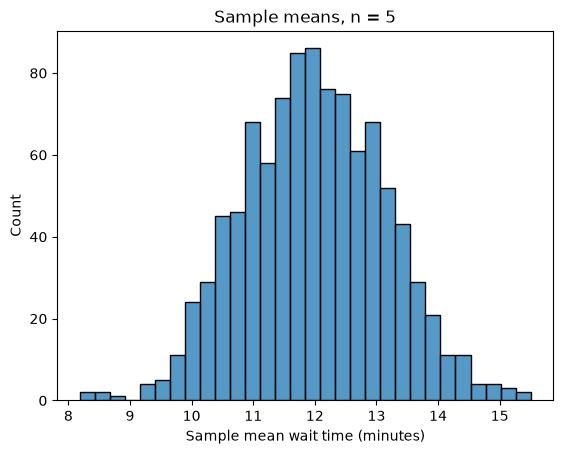

In [2]:
sample_means_5 = np.random.normal(12, 2.5, size=(1000, 5)).mean(axis=1)
sns.histplot(sample_means_5, bins=30)
plt.title('Sample means, n = 5')
plt.xlabel('Sample mean wait time (minutes)')
plt.show()

b) Repeat part a) for sample sizes $n = 30$ and $n = 100$. Plot all three histograms. Describe how the distribution of sample means changes as $n$ increases.

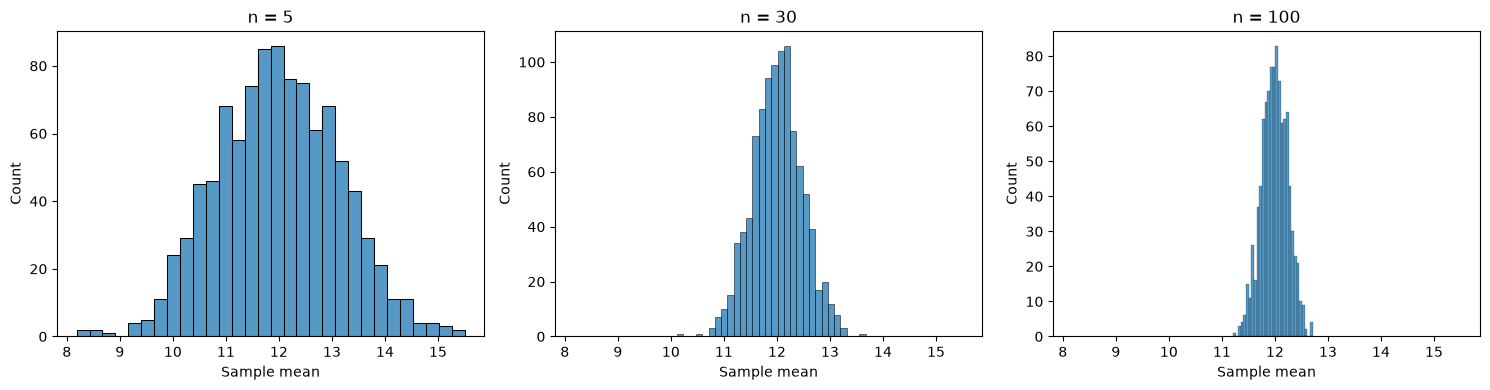

In [3]:
sample_means_30 = np.random.normal(12, 2.5, size=(1000, 30)).mean(axis=1)
sample_means_100 = np.random.normal(12, 2.5, size=(1000, 100)).mean(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, means, n in zip(axes, [sample_means_5, sample_means_30, sample_means_100], [5, 30, 100]):
    sns.histplot(means, bins=30, ax=ax)
    ax.set_title(f'n = {n}')
    ax.set_xlabel('Sample mean')
plt.tight_layout()
plt.show()

All three histograms are bell-shaped and centered at $\mu = 12$. As $n$ increases the distribution gets narrower: sample means from larger samples land closer to 12.

c) Compute the standard deviation of the sample means for each sample size ($n = 5$, $n = 30$, $n = 100$).

In [4]:
print(f'SD of sample means (n=5):   {np.std(sample_means_5):.3f}')
print(f'SD of sample means (n=30):  {np.std(sample_means_30):.3f}')
print(f'SD of sample means (n=100): {np.std(sample_means_100):.3f}')

SD of sample means (n=5):   1.149
SD of sample means (n=30):  0.469
SD of sample means (n=100): 0.246


d) Compute the standard error $\sigma / \sqrt{n}$ for each sample size. Compare these values to the standard deviations you computed in part c).

In [5]:
sigma = 2.5
for n in [5, 30, 100]:
    print(f'Standard error (n={n}): {sigma / np.sqrt(n):.3f}')

Standard error (n=5): 1.118
Standard error (n=30): 0.456
Standard error (n=100): 0.250


The standard errors are $2.5/\sqrt{5} = 1.118$, $2.5/\sqrt{30} = 0.456$, and $2.5/\sqrt{100} = 0.250$. The standard deviations of the simulated sample means (1.149, 0.469, and 0.246 here) are very close. The small differences come from using 1,000 simulated samples rather than infinitely many.

e) In your own words, why does the spread of the sampling distribution decrease as $n$ increases?

In a larger sample, an unusually long wait is more likely to be offset by an unusually short one, so the average cancels out much of the variation in individual observations. The spread of the sample mean is $\sigma / \sqrt{n}$, so it keeps shrinking as $n$ grows. To cut the spread in half you need four times as many observations.

## Q2. The Central Limit Theorem with a Skewed Population

Now consider a different scenario. Wait times at a busy food truck follow an **exponential distribution** with a mean of 5 minutes. This distribution is skewed right: most waits are short, but some are very long. Use `np.random.exponential(5, size=n)` to draw `n` observations from this population.

a) Draw 10,000 observations from this population and plot the histogram. Describe the shape. Is it normal?

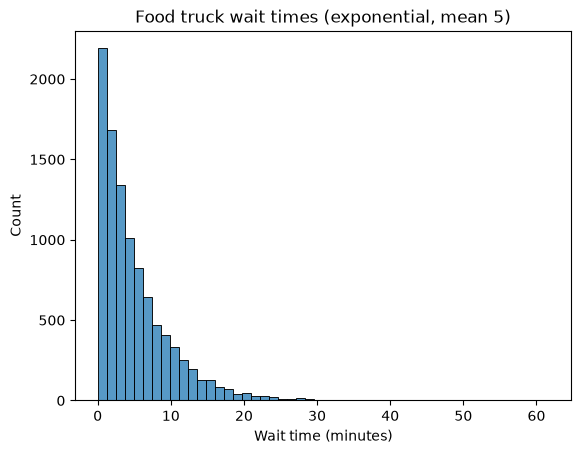

In [6]:
population_exp = np.random.exponential(5, size=10000)
sns.histplot(population_exp, bins=50)
plt.title('Food truck wait times (exponential, mean 5)')
plt.xlabel('Wait time (minutes)')
plt.show()

Not normal. The peak is at zero and there is a long tail to the right: most waits are a few minutes, but some are 20 minutes or more.

b) Take 1,000 samples of size $n = 5$ from this population. Compute the mean of each sample and plot a histogram of the sample means.

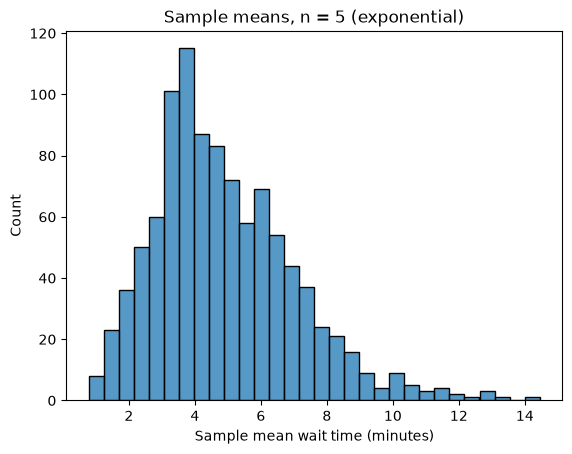

In [7]:
sample_means_exp_5 = np.random.exponential(5, size=(1000, 5)).mean(axis=1)
sns.histplot(sample_means_exp_5, bins=30)
plt.title('Sample means, n = 5 (exponential)')
plt.xlabel('Sample mean wait time (minutes)')
plt.show()

c) Repeat part b) for $n = 30$. Plot the histogram and describe how the shape changed compared to $n = 5$.

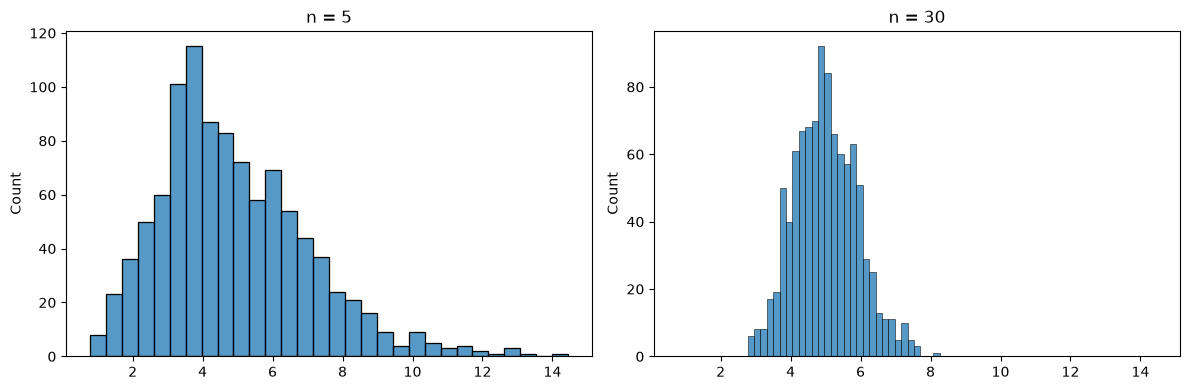

In [8]:
sample_means_exp_30 = np.random.exponential(5, size=(1000, 30)).mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sns.histplot(sample_means_exp_5, bins=30, ax=axes[0])
axes[0].set_title('n = 5')
sns.histplot(sample_means_exp_30, bins=30, ax=axes[1])
axes[1].set_title('n = 30')
plt.tight_layout()
plt.show()

At $n = 5$ the sample means are still skewed right, though much less than the population. At $n = 30$ the histogram is close to a symmetric bell centered at 5, and it is narrower.

d) For both $n = 5$ and $n = 30$, compare the standard deviation of the sample means to the standard error $\sigma / \sqrt{n}$. For the exponential distribution, the population standard deviation equals the mean, so $\sigma = 5$.

In [9]:
sigma_exp = 5
print(f'n=5:  SD of sample means {np.std(sample_means_exp_5):.3f} | standard error {sigma_exp / np.sqrt(5):.3f}')
print(f'n=30: SD of sample means {np.std(sample_means_exp_30):.3f} | standard error {sigma_exp / np.sqrt(30):.3f}')

n=5:  SD of sample means 2.134 | standard error 2.236
n=30: SD of sample means 0.907 | standard error 0.913


The standard errors are $5/\sqrt{5} = 2.236$ and $5/\sqrt{30} = 0.913$. The simulated standard deviations (2.134 and 0.907 here) are close. The formula $\sigma/\sqrt{n}$ works even though the population is not normal.

e) In your own words, what does the Central Limit Theorem guarantee about the shape of the sampling distribution, regardless of the population shape?

As the sample size grows, the distribution of the sample mean gets closer and closer to a normal distribution, centered on the population mean $\mu$ with standard deviation $\sigma / \sqrt{n}$. This holds whatever the shape of the population, as long as the observations are independent draws from it.

## Q3. The Central Limit Theorem with a Bimodal Population

A coffee shop has two types of customers: those who order just a drink (mean spending of 4 dollars, standard deviation 1) and those who order a drink plus food (mean spending of 12 dollars, standard deviation 1.5). About half of customers fall into each group. The function below draws `n` observations from this bimodal population.

In [10]:
def bimodal_sample(n):
    group = np.random.choice([0, 1], size=n)
    drink = np.random.normal(4, 1, n)
    food = np.random.normal(12, 1.5, n)
    return np.where(group == 0, drink, food)

a) Draw 10,000 observations from this population and plot the histogram. Describe the shape. How many peaks does it have?

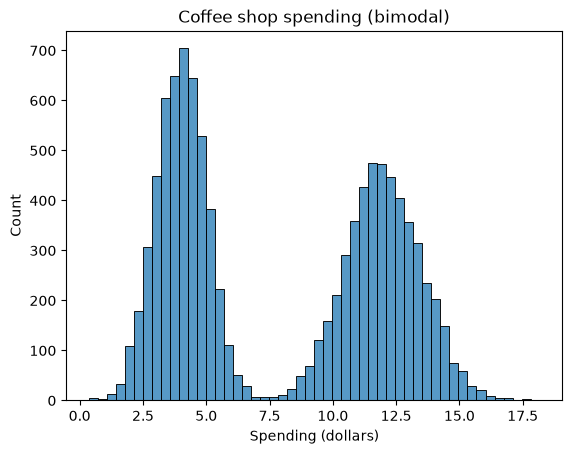

In [11]:
population_bimodal = bimodal_sample(10000)
sns.histplot(population_bimodal, bins=50)
plt.title('Coffee shop spending (bimodal)')
plt.xlabel('Spending (dollars)')
plt.show()

Two peaks: one near 4 dollars (drink only) and one near 12 dollars (drink plus food), with almost no customers in between around 8 dollars. This is clearly not normal.

b) Take 1,000 samples of size $n = 5$ from this population. Compute the mean of each sample and plot a histogram of the sample means.

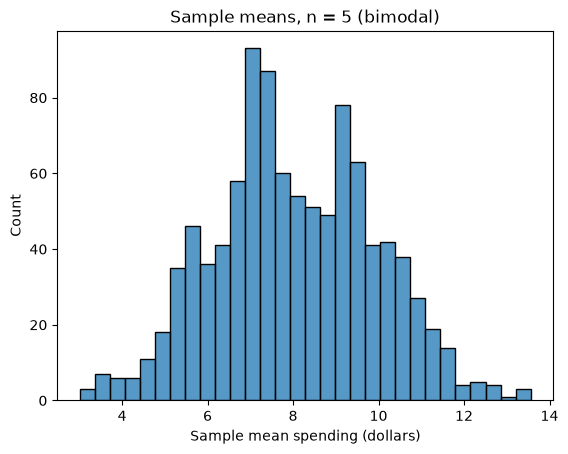

In [12]:
sample_means_bi_5 = np.array([bimodal_sample(5).mean() for _ in range(1000)])
sns.histplot(sample_means_bi_5, bins=30)
plt.title('Sample means, n = 5 (bimodal)')
plt.xlabel('Sample mean spending (dollars)')
plt.show()

c) Repeat part b) for $n = 30$. Plot the histogram and describe how the shape changed compared to the population and to $n = 5$.

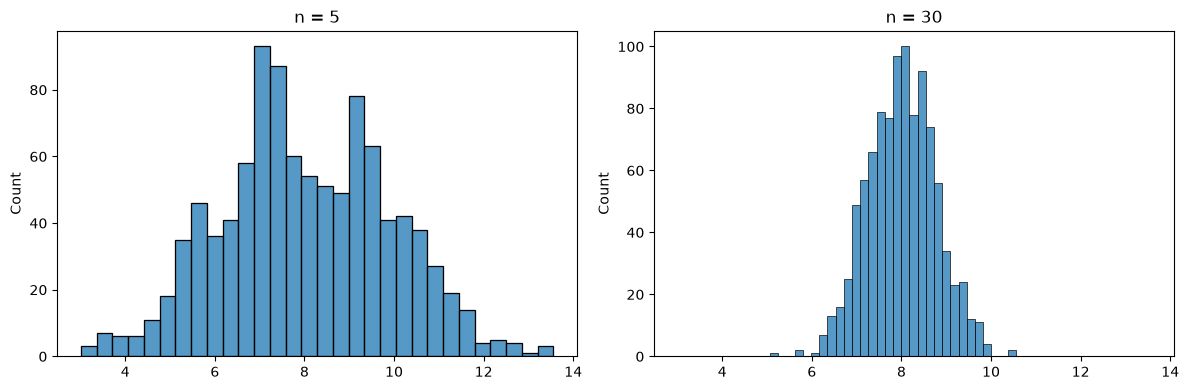

In [13]:
sample_means_bi_30 = np.array([bimodal_sample(30).mean() for _ in range(1000)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sns.histplot(sample_means_bi_5, bins=30, ax=axes[0])
axes[0].set_title('n = 5')
sns.histplot(sample_means_bi_30, bins=30, ax=axes[1])
axes[1].set_title('n = 30')
plt.tight_layout()
plt.show()

At $n = 5$ the population's two separate peaks are gone: the sample means center near 8 dollars, the overall mean, but the histogram is wide and lumpy, with several small bumps (a sample of 5 can have anywhere from 0 to 5 food customers). At $n = 30$ it is a smooth, narrow bell curve centered at 8, even though almost no single customer spends 8 dollars.

d) Compute the standard deviation of your 10,000 population observations from part a) and use it as $\sigma$. Then compare the standard deviation of your sample means (for $n = 5$ and $n = 30$) to the standard error $\sigma / \sqrt{n}$.

In [14]:
sigma_bi = np.std(population_bimodal)
print(f'Population SD (10,000 draws): {sigma_bi:.3f}')
print(f'n=5:  SD of sample means {np.std(sample_means_bi_5):.3f} | standard error {sigma_bi / np.sqrt(5):.3f}')
print(f'n=30: SD of sample means {np.std(sample_means_bi_30):.3f} | standard error {sigma_bi / np.sqrt(30):.3f}')

Population SD (10,000 draws): 4.208
n=5:  SD of sample means 1.877 | standard error 1.882
n=30: SD of sample means 0.756 | standard error 0.768


The population standard deviation is about 4.2 (4.208 here), mostly because the two groups are 8 dollars apart. The standard errors are $4.21/\sqrt{5} \approx 1.88$ and $4.21/\sqrt{30} \approx 0.77$, and the simulated standard deviations of the sample means (1.877 and 0.756 here) are close to both. The formula works here too.

e) Across all three questions, you started with a normal population, a skewed population, and a bimodal population. What happened to the sampling distribution of the mean in each case as $n$ increased? What does this tell you about how general the Central Limit Theorem is?

In all three cases the sampling distribution of the mean became a narrower bell curve as $n$ increased:

- **Normal (Q1):** the sample means were bell-shaped at every $n$, and their spread shrank.
- **Skewed (Q2):** the skew faded, and by $n = 30$ the sample means looked close to normal.
- **Bimodal (Q3):** the two peaks merged into one bell curve centered between them.

In every case the spread of the sample means matched the standard error $\sigma / \sqrt{n}$. The CLT does not depend on the shape of the population, which is why we can make inferences about a population mean without knowing what the population looks like.